# 03 - Train the letter classifier

**Goal:** 63 normalized keypoint features -> one of 28 classes (A-Z, `del`, `space`). "No hand detected" is NOTHING and never reaches the model.

**Plan:** (1) load and block-split  (2) show why a random split lies  (3) scikit-learn baseline  (4) PyTorch MLP  (5) design experiments  (6) per-class errors  (7) save the model

### Concepts used here
- **Train / validation / test.** Train = the model learns from it. Validation = used to compare designs and pick epochs. Test = touched once at the end; here that is **my own webcam photos (notebook 04)**, because validation frames come from the same signer, camera and room as training.
- **Logits -> softmax -> cross-entropy.** The network outputs 28 raw scores (logits). Softmax turns them into probabilities that sum to 1. Cross-entropy is `-log(probability given to the correct class)`: confident and right is near 0, confident and wrong is huge. `nn.CrossEntropyLoss` includes the softmax, so the model outputs raw logits.
- **Overfitting.** Train accuracy keeps rising while validation stalls or falls: the model is memorizing, not learning shapes.
- **A suspiciously high validation score** (say 99%+) is a warning, not a win. It usually means leakage (near-twin frames on both sides) or an easy validation set.

In [11]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

CSV_PATH = "../data/processed/keypoints_conf03_stride1.csv"   # <- swap to keypoints_conf03_stride1.csv after the rerun
SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)

df = pd.read_csv(CSV_PATH)
df = df[df.cls != "nothing"].copy()                    # the single false-positive row is dropped
feature_cols = [f"{n}{i}" for i in range(21) for n in "xyz"]
CLASS_NAMES = sorted(df.cls.unique())
K = len(CLASS_NAMES)
cls_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
print(df.shape, "|", K, "classes")

X = df[feature_cols].to_numpy(np.float32)
y = df.cls.map(cls_to_idx).to_numpy()

(66840, 67) | 28 classes


## 1. Block split
Per class: frames **<= 2100 train**, frames **>= 2300 validation**, frames 2101-2299 thrown away as a **buffer**. Neighbouring frames are near-twins for hundreds of frames (notebook 01 decay curve), so without the buffer, the last training frame and the first validation frame could be almost the same picture.

In [12]:
frame = df.frame.to_numpy()
tr = frame <= 2100
va = frame >= 2300
Xtr, ytr, Xva, yva = X[tr], y[tr], X[va], y[va]
print("train:", Xtr.shape, "| val:", Xva.shape, "| buffer dropped:", int((~tr & ~va).sum()))

# Standardize with TRAIN statistics only (val must not influence anything about training)
mean = Xtr.mean(0)
std = Xtr.std(0); std[std < 1e-6] = 1.0                # wrist columns are constant 0
Xtr_s, Xva_s = (Xtr - mean) / std, (Xva - mean) / std

train: (53255, 63) | val: (9451, 63) | buffer dropped: 4134


## 2. Why a random split lies
Same model, same data, two splits. A 1-nearest-neighbour classifier does no learning at all; it copies the label of the most similar training row. On a random split, every validation frame has a near-twin in train, so it should look brilliant. On the block split it can't cheat.

In [13]:
Xr_tr, Xr_va, yr_tr, yr_va = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
sc = StandardScaler().fit(Xr_tr)

knn_rand = KNeighborsClassifier(n_neighbors=1, n_jobs=-1).fit(sc.transform(Xr_tr), yr_tr)
knn_block = KNeighborsClassifier(n_neighbors=1, n_jobs=-1).fit(Xtr_s, ytr)
acc_rand = accuracy_score(yr_va, knn_rand.predict(sc.transform(Xr_va)))
acc_block = accuracy_score(yva, knn_block.predict(Xva_s))
print(f"1-NN, RANDOM split : {acc_rand:.3f}")
print(f"1-NN, BLOCK  split : {acc_block:.3f}")

1-NN, RANDOM split : 0.985
1-NN, BLOCK  split : 0.874


**Finding (fill in):** how big is the gap, and what does it say about how much of the random-split score was memorization?

## 3. Baseline: logistic regression
A linear model (no hidden layers). If the MLP can't beat this clearly, the extra complexity isn't earning its place. Always run a baseline first.

In [14]:
def report(name, ytrue, ypred):
    print(f"{name}: accuracy {accuracy_score(ytrue, ypred):.3f} | macro-F1 {f1_score(ytrue, ypred, average='macro'):.3f}")

logreg = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr_s, ytr)
report("logreg train", ytr, logreg.predict(Xtr_s))
report("logreg val  ", yva, logreg.predict(Xva_s))

logreg train: accuracy 0.983 | macro-F1 0.982
logreg val  : accuracy 0.916 | macro-F1 0.903


## 4. PyTorch MLP
`63 -> hidden layers (ReLU) -> 28 logits`. Design choices and why:
- **ReLU** between layers so the network can bend decision boundaries (without it, stacked linear layers collapse into one linear layer).
- **Dropout** randomly switches off units during training so no single unit can carry a memorized pattern. It is off in `eval()` mode.
- **Weight decay** gently shrinks the weights; another brake on overfitting.
- **Class weights** (inverse frequency in train) so rare classes (N, space) count as much as common ones.
- **Adam**, lr 1e-3, batch 256: a standard starting point, not a tuned value.
- I pick the epoch with the best validation **macro-F1** (every class counts equally).

In [15]:
Xtr_t, ytr_t = torch.tensor(Xtr_s), torch.tensor(ytr, dtype=torch.long)
Xva_t, yva_t = torch.tensor(Xva_s), torch.tensor(yva, dtype=torch.long)

counts = np.bincount(ytr, minlength=K).astype(np.float32)
class_w = torch.tensor(len(ytr) / (K * counts))        # inverse-frequency weights

def build(hidden, dropout):
    layers, d = [], 63
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
        d = h
    layers.append(nn.Linear(d, K))                      # raw logits, no softmax here
    return nn.Sequential(*layers)

def train_mlp(hidden=(128, 64), dropout=0.2, wd=1e-4, lr=1e-3, epochs=30, bs=256, seed=SEED, verbose=False):
    torch.manual_seed(seed)
    model = build(hidden, dropout)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.CrossEntropyLoss(weight=class_w)
    hist, best_f1, best_state = [], -1.0, None
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss_fn(model(Xtr_t[idx]), ytr_t[idx]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            ltr, lva = model(Xtr_t), model(Xva_t)
            row = dict(epoch=ep + 1,
                       train_loss=loss_fn(ltr, ytr_t).item(), val_loss=loss_fn(lva, yva_t).item(),
                       train_acc=(ltr.argmax(1) == ytr_t).float().mean().item(),
                       val_acc=(lva.argmax(1) == yva_t).float().mean().item(),
                       val_f1=f1_score(yva, lva.argmax(1).numpy(), average="macro"))
        hist.append(row)
        if row["val_f1"] > best_f1:
            best_f1 = row["val_f1"]
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        if verbose and (ep + 1) % 5 == 0:
            print({k: round(v, 3) for k, v in row.items()})
    return model, pd.DataFrame(hist), best_state

model, hist, best_state = train_mlp(verbose=True)
print("best val macro-F1:", round(hist.val_f1.max(), 3), "at epoch", int(hist.val_f1.idxmax()) + 1)

{'epoch': 5, 'train_loss': 0.141, 'val_loss': 0.486, 'train_acc': 0.965, 'val_acc': 0.894, 'val_f1': 0.879}
{'epoch': 10, 'train_loss': 0.09, 'val_loss': 0.461, 'train_acc': 0.976, 'val_acc': 0.91, 'val_f1': 0.895}
{'epoch': 15, 'train_loss': 0.067, 'val_loss': 0.456, 'train_acc': 0.982, 'val_acc': 0.918, 'val_f1': 0.903}
{'epoch': 20, 'train_loss': 0.056, 'val_loss': 0.446, 'train_acc': 0.986, 'val_acc': 0.93, 'val_f1': 0.919}
{'epoch': 25, 'train_loss': 0.046, 'val_loss': 0.449, 'train_acc': 0.988, 'val_acc': 0.928, 'val_f1': 0.916}
{'epoch': 30, 'train_loss': 0.045, 'val_loss': 0.487, 'train_acc': 0.988, 'val_acc': 0.925, 'val_f1': 0.912}
best val macro-F1: 0.92 at epoch 27


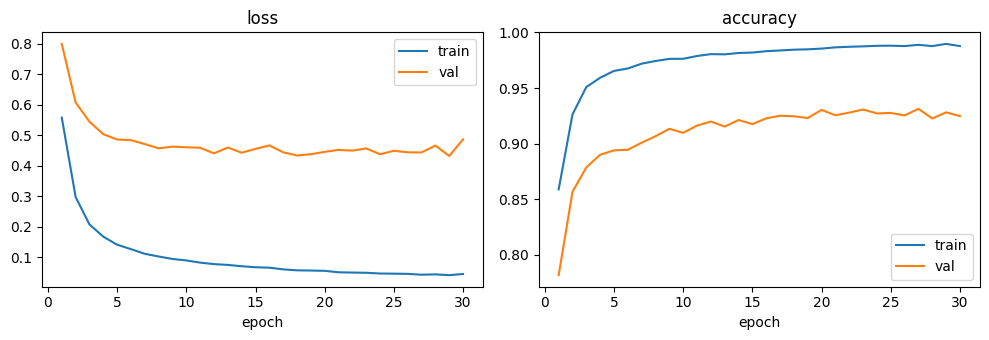

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist.epoch, hist.train_loss, label="train"); ax[0].plot(hist.epoch, hist.val_loss, label="val")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist.epoch, hist.train_acc, label="train"); ax[1].plot(hist.epoch, hist.val_acc, label="val")
ax[1].set_title("accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

**Finding (fill in):** do the train and validation curves separate? At what epoch? Is the MLP clearly better than the logistic baseline? Is the validation score suspiciously high?

## 5. Design experiments
Change one thing at a time and compare **validation macro-F1** (and the train-vs-val gap). Differences of a point or two are noise because the validation frames are clumped near-twins, so look for clear differences.

In [17]:
configs = {
    "small (32)":           dict(hidden=(32,)),
    "base (128,64)":        dict(hidden=(128, 64)),
    "wide (256,128)":       dict(hidden=(256, 128)),
    "deep (128,128,64)":    dict(hidden=(128, 128, 64)),
    "no dropout/decay":     dict(hidden=(128, 64), dropout=0.0, wd=0.0),
    "heavy dropout 0.5":    dict(hidden=(128, 64), dropout=0.5),
}
results = {}
for name, cfg in configs.items():
    m, h, st = train_mlp(**cfg)
    results[name] = (cfg, h, st)
    last = h.iloc[-1]
    print(f"{name:20s} best val F1 {h.val_f1.max():.3f} | final train acc {last.train_acc:.3f} | final val acc {last.val_acc:.3f}")

small (32)           best val F1 0.902 | final train acc 0.975 | final val acc 0.915
base (128,64)        best val F1 0.920 | final train acc 0.988 | final val acc 0.925
wide (256,128)       best val F1 0.921 | final train acc 0.994 | final val acc 0.931
deep (128,128,64)    best val F1 0.920 | final train acc 0.990 | final val acc 0.926
no dropout/decay     best val F1 0.914 | final train acc 0.993 | final val acc 0.889
heavy dropout 0.5    best val F1 0.901 | final train acc 0.975 | final val acc 0.908


**Finding (fill in):** which knob mattered most? Did removing dropout/decay widen the train-val gap? Did a bigger network help or only memorize more? Which config do I choose, and why?

## 6. Where does it fail?
Overall accuracy hides weak letters. Per-class accuracy and the confusion matrix show **which letters get mistaken for which**. Expect look-alike fists (A/E/M/N/S/T), and J/Z (motion letters, seen as stills) to confuse.

In [18]:
BEST = "base (128,64)" # change this to your own choice if you prefer
cfg, h_best, st_best = results[BEST]
final = build(cfg["hidden"], cfg.get("dropout", 0.2)); final.load_state_dict(st_best); final.eval()
print("using:", BEST)

with torch.no_grad():
    pred = final(Xva_t).argmax(1).numpy()
report("MLP val", yva, pred)
report("logreg val", yva, logreg.predict(Xva_s))

per_class = pd.Series({CLASS_NAMES[c]: (pred[yva == c] == c).mean() for c in range(K)}).sort_values()
print(per_class.round(2).to_string())

using: base (128,64)
MLP val: accuracy 0.931 | macro-F1 0.920
logreg val: accuracy 0.916 | macro-F1 0.903
N        0.64
A        0.78
M        0.79
P        0.79
T        0.82
U        0.88
R        0.89
D        0.91
I        0.91
S        0.91
E        0.93
Z        0.95
G        0.96
W        0.96
O        0.97
X        0.97
Q        0.97
J        0.97
del      0.97
space    0.97
Y        0.98
L        0.98
K        0.98
B        0.98
V        0.98
H        0.99
C        1.00
F        1.00


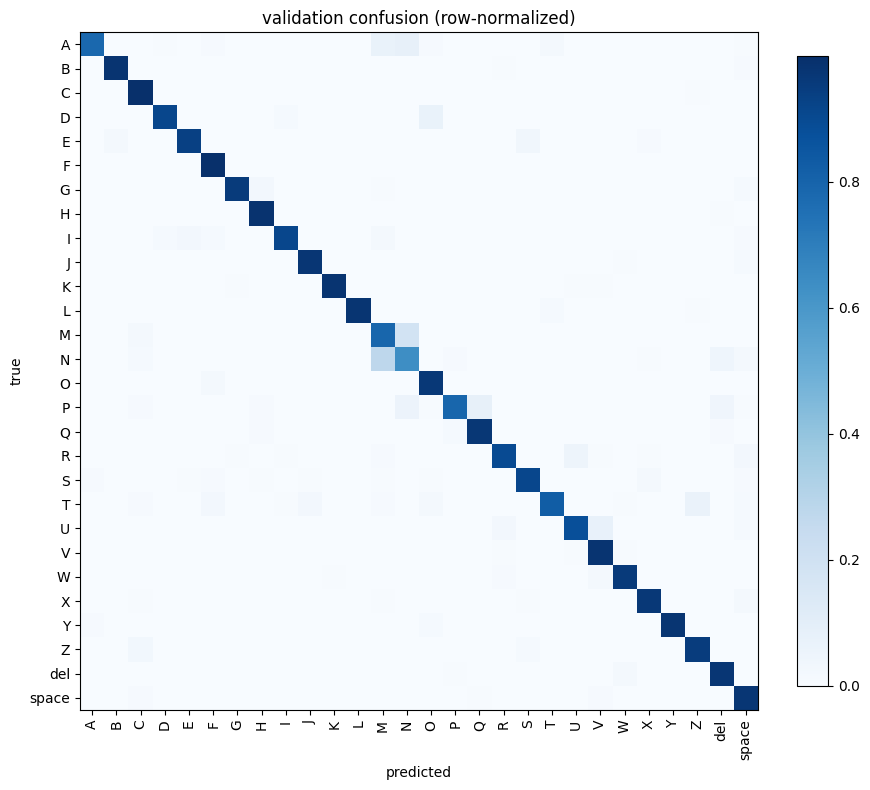

top confusions (true -> predicted, share of true class):
  N -> M: 0.27
  M -> N: 0.19
  P -> Q: 0.08
  A -> N: 0.08
  U -> V: 0.07
  A -> M: 0.07
  D -> O: 0.07
  T -> Z: 0.06
  P -> N: 0.06
  R -> U: 0.05


In [19]:
cm = confusion_matrix(yva, pred, normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im, fraction=0.04)
ax.set_xticks(range(K)); ax.set_xticklabels(CLASS_NAMES, rotation=90)
ax.set_yticks(range(K)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("validation confusion (row-normalized)")
plt.tight_layout(); plt.show()

off = [(CLASS_NAMES[i], CLASS_NAMES[j], cm[i, j]) for i in range(K) for j in range(K) if i != j]
print("top confusions (true -> predicted, share of true class):")
for t, p, v in sorted(off, key=lambda r: -r[2])[:10]:
    print(f"  {t} -> {p}: {v:.2f}")

**Finding (fill in):** worst classes, the top confused pairs, and whether they are look-alike shapes. Are J and Z weak, as expected? What would I try next (more data for weak letters, a confidence threshold, own webcam data)?

## 7. Save the model
The live app must reproduce **exactly** the same preprocessing: normalize (notebook 02) with the same detector settings, then standardize with these train mean/std, then the network. All of it is saved together.

In [20]:
Path("../models").mkdir(exist_ok=True)
torch.save({
    "state_dict": st_best,
    "hidden": cfg["hidden"], "dropout": cfg.get("dropout", 0.2),
    "mean": mean, "std": std,
    "classes": CLASS_NAMES, "feature_cols": feature_cols,
    "csv_used": CSV_PATH,
}, "../models/mlp_v1.pt")
print("saved ../models/mlp_v1.pt")

saved ../models/mlp_v1.pt


## Findings
- **Random vs block split:** 1-NN scores 0.985 on a random split but 0.874 on the block split, so about 11 points came from near-twin memorization. The block split with a 200-frame buffer is what makes validation honest.
- **Baseline vs MLP:** logistic regression 0.903 macro-F1, MLP 0.920. Keypoints are mostly linearly separable, so the MLP adds about 2 points.
- **Design:** size didn't matter (32 is slightly worse; 128/64, 256/128 and 128/128/64 tie at ~0.92). Removing dropout and weight decay hurt the most (final val acc 0.889 vs 0.925); dropout 0.5 was too strong. Chose (128, 64) with dropout 0.2: tied for best and simplest.
- **Overfitting:** train acc 0.988 vs val 0.925; val loss rises after epoch ~20.
- **Weakest classes:** N 0.64, A 0.78, M 0.79, P 0.79, T 0.82; N<->M and M->N are the top confusions (thumb-tucked fists). J and Z are fine as stills.
- **Conf 0.3 vs 0.5:** scores dropped ~2 points, most likely because the added frames make validation harder, not because the model got worse.
- **What validation doesn't tell me:** same signer, camera and room. The real test is notebook 04.